# **Extra: Decoding JEPA Latents into Images**
---

A JEPA has **no decoder**: the encoder was never asked to keep the information needed to redraw the frame, only the information that makes the next latent predictable. To understand what the latents contain, this notebook trains a decoder **afterwards**, as a qualitative tool.

## **Theory: a Decoder as a Probe in Pixel Space**

The decoder $D_\omega$ is trained on the **frozen** target encoder of `1-full_jepa_training.ipynb`:

$$\hat{x} = D_\omega\big(\mathrm{sg}(E_{\bar\theta}(x))\big), \qquad \mathcal{L}(\omega) = \frac{1}{B}\sum_{i=1}^{B} \big\lVert \hat{x}^{(i)} - x^{(i)} \big\rVert_2^2$$

(per-sample sum of squared pixel errors, as the reconstruction term of the VAE). The latents are computed under `no_grad`: **no gradient reaches the encoder**, so training the decoder cannot change the representation or the world model. The decoder is just a nonlinear *probe* that maps latents back to pixels, the image-space analogue of the linear state probes of the evaluation protocol.

How to read the results:

- **Sharp cart and pole** in the reconstructions: position and angle are encoded precisely.
- **Blurry or averaged parts**: information the latent does not hold (or holds only coarsely). For a JEPA this is expected and not a defect: anything that does not help predict the future can be discarded.
- **Latent traversals**: moving along the principal directions of the latent space and decoding shows which visual factor each direction controls.

The decoder uses the World Models deconv stack (the same as the VAE decoder), so the reconstruction quality can be put side by side with the VAE's. Note the difference in purpose: the VAE's encoder was *trained* to reconstruct, here the encoder is fixed and only the decoder adapts. This decoder is **not part of the quantitative evaluation**; it is only used for the qualitative section (Test 5) of the evaluation notebook.

## **Setup and Imports**
---

In [1]:
from jepacartpole.config import ConfigLatentDecoder
from jepacartpole.full_jepa import (
    LatentDecoder,
    load_full_jepa,
    load_latent_decoder,
    train_latent_decoder,
    load_episodes,
    encode_episodes,
    frames_to_device,
    plot_decoder_training_curves,
    plot_decoder_reconstructions,
    plot_latent_traversals
)
from jepacartpole.vae import VAE
from jepacartpole.utils import get_device, load_checkpoint, count_parameters, set_seed, get_checkpoint_dir, get_data_dir

import h5py
import numpy as np
import torch
import matplotlib.pyplot as plt

set_seed(42)
DEVICE = get_device()
print(f"Device: {DEVICE}")

Device: cuda


## **Configuration and Frozen JEPA**
---

The decoder is trained on the training episodes of the JEPA and validated on its validation episodes (stored in the JEPA checkpoint).

In [2]:
config = ConfigLatentDecoder()

FRAMES_PATH = get_data_dir('vae') / 'vae_data.h5'
JEPA_CHECKPOINT = get_checkpoint_dir() / 'full_jepa.pth'

jepa, jepa_ckpt = load_full_jepa(JEPA_CHECKPOINT, DEVICE)
for p in jepa.parameters():
    p.requires_grad = False

with h5py.File(FRAMES_PATH, 'r') as h5f:
    num_episodes = h5f['images'].shape[0]
VAL_EPISODES = np.asarray(jepa_ckpt['val_episodes'])
TRAIN_EPISODES = np.setdiff1d(np.arange(num_episodes), VAL_EPISODES)

print(f"JEPA: {JEPA_CHECKPOINT} (latent_dim={jepa.config.latent_dim})")
print(f"Train episodes: {len(TRAIN_EPISODES)}  |  val episodes: {len(VAL_EPISODES)}")
print(f"Decoder config: {config}")

JEPA: /teamspace/studios/this_studio/jepa_cart_pole/checkpoints/full_jepa.pth (latent_dim=32)
Train episodes: 450  |  val episodes: 50
Decoder config: ConfigLatentDecoder(batch_size=100, epochs=10, learning_rate=0.0001, weight_decay=1e-06)


## **Decoder Training**
---

Checkpoints: `checkpoints/latent_decoder_latest.pth` after every epoch, `checkpoints/latent_decoder.pth` at the end. The PSNR on validation frames, $10\log_{10}(1/\mathrm{MSE})$ for pixels in $[0, 1]$, is reported every epoch.

In [3]:
decoder = LatentDecoder(jepa.config.latent_dim, jepa.config.image_channels).to(DEVICE)
print(f"Decoder trainable parameters: {count_parameters(decoder):,}")

Decoder trainable parameters: 3,592,803


In [4]:
%%time
history = train_latent_decoder(
    decoder=decoder,
    encoder=jepa,
    config=config,
    train_episodes=TRAIN_EPISODES,
    val_episodes=VAL_EPISODES,
    h5_path=FRAMES_PATH,
    device=DEVICE,
    # epochs=1,
    jepa_checkpoint=str(JEPA_CHECKPOINT)
)

Decoder training: 225,000 train frames, 25,000 val frames, 10 epochs, device cuda


Epoch 1/10: train=249.21  val=186.11  val PSNR=18.20 dB


Epoch 2/10: train=186.04  val=186.10  val PSNR=18.20 dB


Epoch 3/10: train=186.04  val=186.10  val PSNR=18.20 dB


Epoch 4/10: train=186.04  val=186.00  val PSNR=18.20 dB


...

Epoch 6/10: train=3.55  val=1.40  val PSNR=39.44 dB


Epoch 7/10: train=1.02  val=0.77  val PSNR=42.04 dB


Epoch 8/10: train=0.62  val=0.54  val PSNR=43.55 dB


Epoch 9/10: train=0.44  val=0.39  val PSNR=45.00 dB


Epoch 10/10: train=0.34  val=0.32  val PSNR=45.89 dB
Decoder saved to: /teamspace/studios/this_studio/jepa_cart_pole/checkpoints/latent_decoder.pth
CPU times: user 7min 17s, sys: 5.34 s, total: 7min 22s
Wall time: 7min 26s


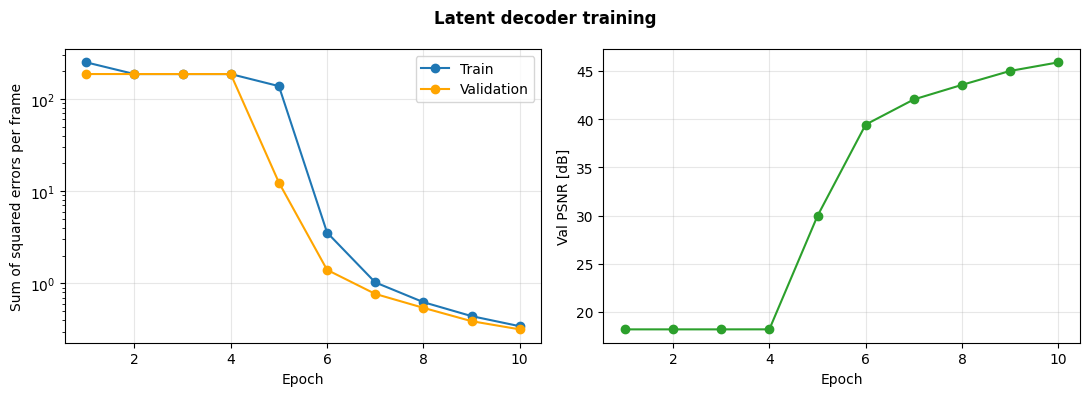

In [5]:
decoder, decoder_ckpt = load_latent_decoder(get_checkpoint_dir() / 'latent_decoder.pth', DEVICE)
fig = plot_decoder_training_curves(decoder_ckpt['history'])
plt.show()

## **Reconstructions**
---

Random validation frames, their reconstruction from the JEPA latent, and (for reference) the VAE reconstruction from its mean latent $\mu$. The PSNR of both models is computed on the same validation frames.

PSNR on 5,000 validation frames:
  JEPA latents + decoder: 46.22 dB
  VAE (μ):                52.03 dB


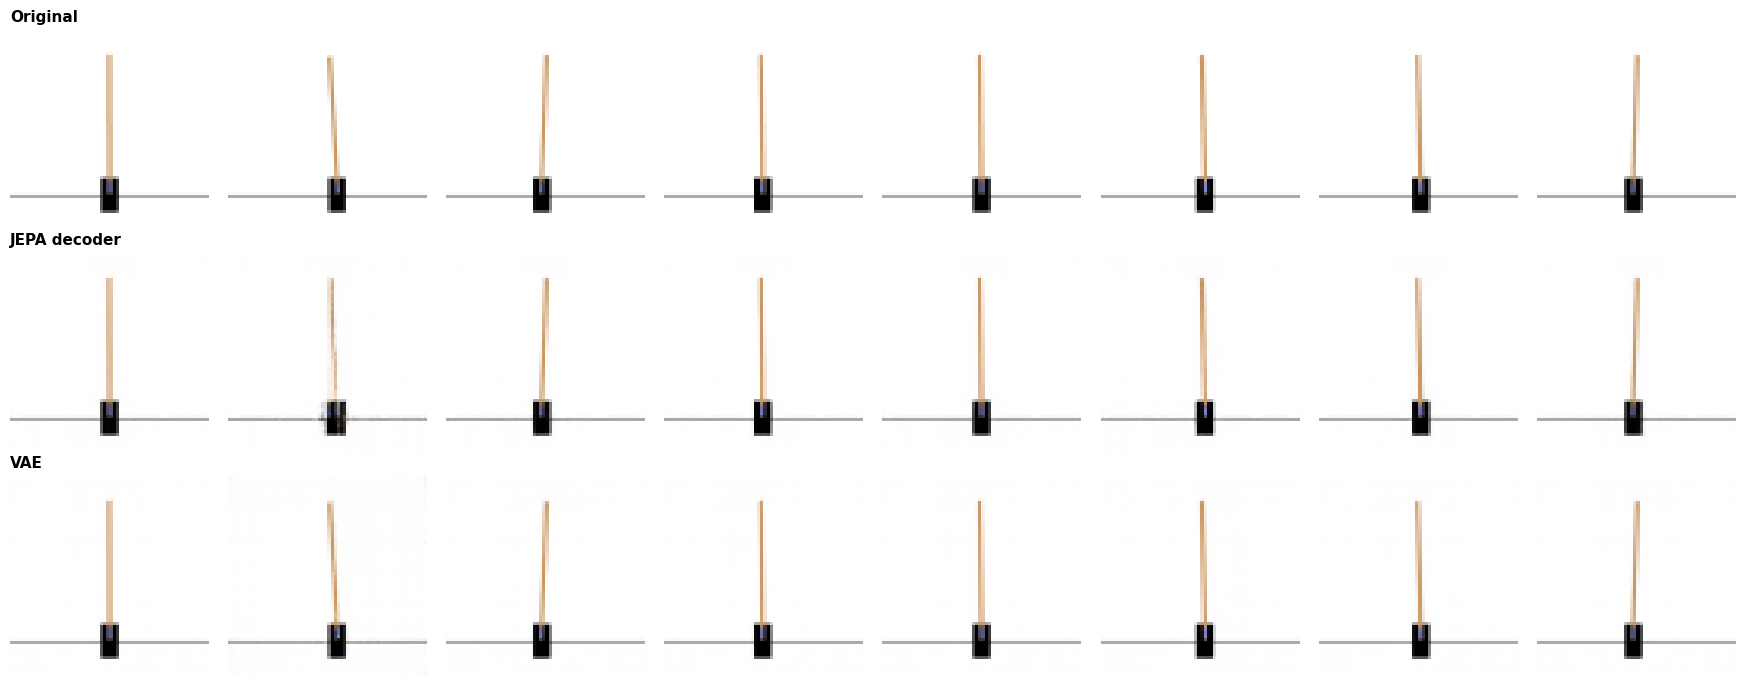

In [6]:
vae_path = get_checkpoint_dir() / 'vae.pth'
vae = VAE(torch.load(vae_path, weights_only=False, map_location='cpu')['config'])
load_checkpoint(vae, vae_path, device=DEVICE)
vae.eval()

val_images = load_episodes(FRAMES_PATH, VAL_EPISODES[:10], keys=('images',))['images']
val_flat = val_images.reshape(-1, *val_images.shape[2:])

@torch.no_grad()
def psnr(encode, decode, frames, batch_size=1000):
    mse = []
    for s in range(0, len(frames), batch_size):
        x = frames_to_device(frames[s:s + batch_size], DEVICE)
        mse.append((decode(encode(x)) - x).pow(2).mean(dim=(1, 2, 3)).cpu())
    return float(10 * torch.log10(1 / torch.cat(mse).mean()))

print(f"PSNR on {len(val_flat):,} validation frames:")
print(f"  JEPA latents + decoder: {psnr(jepa.encode, decoder.decode, val_flat):.2f} dB")
print(f"  VAE (μ):                {psnr(lambda x: vae.encode(x)[0], vae.decode, val_flat):.2f} dB")

rng = np.random.default_rng(0)
sample = val_flat[rng.choice(len(val_flat), 8, replace=False)]
fig = plot_decoder_reconstructions(jepa, decoder, sample, extra={'VAE': (vae, vae)})
plt.show()

## **Decoded Sequence**
---

Consecutive frames of a validation episode and their reconstructions, to check that small motions between frames are preserved.

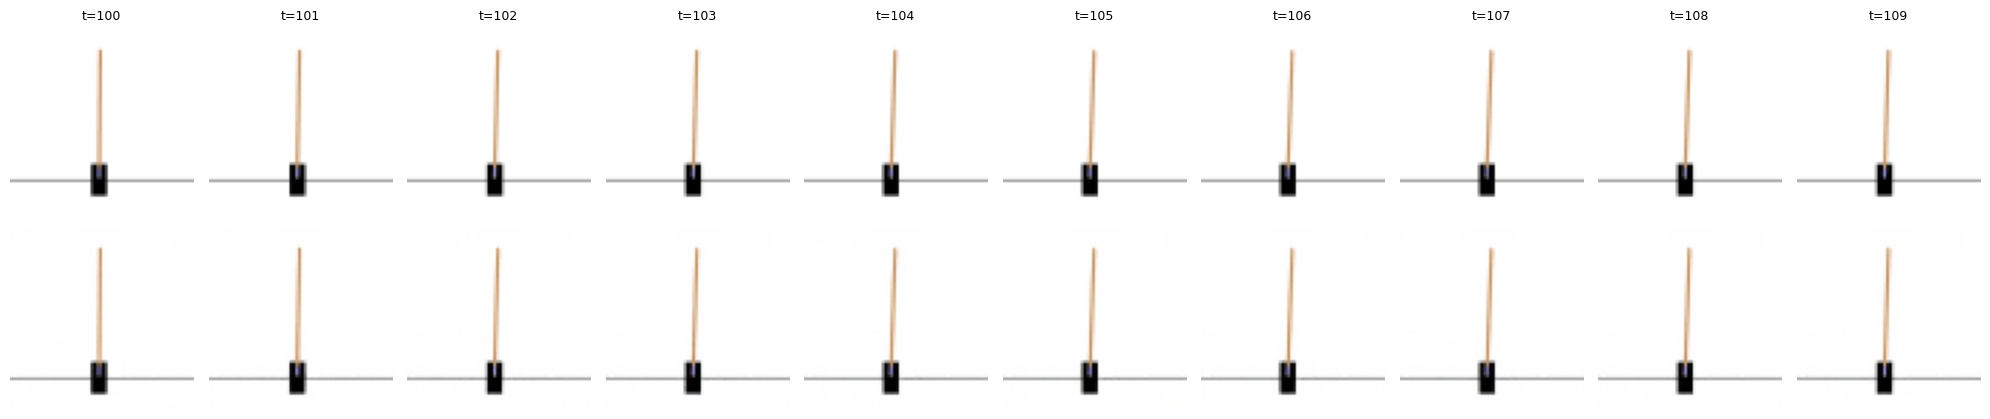

In [9]:
ep, t0, n = 0, 100, 10
frames = val_images[ep, t0:t0 + n]
with torch.no_grad():
    recon = decoder.decode(jepa.encode(frames_to_device(frames, DEVICE))).cpu().permute(0, 2, 3, 1).numpy()

fig, axes = plt.subplots(2, n, figsize=(2.0 * n, 4.4))
for i in range(n):
    axes[0, i].imshow(frames[i])
    axes[1, i].imshow(recon[i])
    axes[0, i].set_title(f't={t0 + i}', fontsize=9)
    for row in range(2):
        axes[row, i].axis('off')
plt.tight_layout()
plt.show()

## **Summary**
---

✓ Trained a decoder on frozen JEPA latents (the encoder is untouched)

✓ Compared reconstructions with the VAE and inspected the principal directions of the latent space

The decoder is used by the qualitative section (Test 5) of `3-full_jepa_evaluation.ipynb` to decode imagined rollouts and counterfactuals.

---

**Decoder checkpoint saved at**: `checkpoints/latent_decoder.pth`